<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Ce notebook réalise en 5 étapes l'analyse complète des données Bottleneck :

1. **Importation** des librairies et chargement des fichiers
2. **Analyse exploratoire** de chaque fichier source
3. **Jonction** des fichiers (ERP + Liaison + Web)
4. **Analyse univariée** des prix (boxplot, Z-Score, IQR)
5. **Analyses métier** : CA, ventes, stocks, marges, corrélations

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [241]:
# Importation de la librairie Pandas
# pandas = manipulation de tableaux de données (comme Excel, mais en Python)
import pandas as pd

In [242]:
# Importation de la librairie plotly express
# plotly = graphiques interactifs
import plotly.express as px

In [243]:
# Importation de la librairie matplotlib et seaborn
# matplotlib = graphiques statiques
# seaborn    = graphiques statistiques élaborés (heatmap, etc.)
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
print(' matplotlib et seaborn importés avec succès')

# Note : plotly était initialement utilisé pour les graphiques interactifs.
# On utilise matplotlib/seaborn qui sont disponibles dans tous les environnements.

 matplotlib et seaborn importés avec succès


In [244]:
# Instruction permettant d'afficher TOUTES les colonnes d'un dataframe
# Sans cette option, pandas tronque les colonnes avec des '...'
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 60)

# Importation des autres librairies
import numpy as np               # calculs mathématiques
import seaborn as sns            # heatmap de corrélations
import matplotlib.pyplot as plt  # affichage des graphiques

print(' Toutes les librairies sont importées avec succès')

 Toutes les librairies sont importées avec succès


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [245]:
# Importation du fichier web.xlsx
df_web = pd.read_excel('web.xlsx')

# Importation du fichier erp.xlsx
df_erp = pd.read_excel('erp.xlsx')

# Importation du fichier liaison.xlsx
df_liaison = pd.read_excel('liaison.xlsx')

print(' Fichiers chargés avec succès')
print(f'   → web.xlsx     : {df_web.shape[0]} lignes, {df_web.shape[1]} colonnes')
print(f'   → erp.xlsx     : {df_erp.shape[0]} lignes, {df_erp.shape[1]} colonnes')
print(f'   → liaison.xlsx : {df_liaison.shape[0]} lignes, {df_liaison.shape[1]} colonnes')

 Fichiers chargés avec succès
   → web.xlsx     : 1513 lignes, 29 colonnes
   → erp.xlsx     : 825 lignes, 6 colonnes
   → liaison.xlsx : 825 lignes, 2 colonnes


C:\Users\sabah\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning:

Unknown extension is not supported and will be removed

C:\Users\sabah\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning:

Unknown extension is not supported and will be removed

C:\Users\sabah\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning:

Unknown extension is not supported and will be removed



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [246]:
# Afficher les dimensions du dataset
# .shape[0] = lignes | .shape[1] = colonnes
print('Le tableau comporte {} observation(s) ou article(s)'.format(df_erp.shape[0]))
print('Le tableau comporte {} colonne(s)'.format(df_erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [247]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes (int64, float64, object...)
# Le nombre de valeurs présentes dans chacune des colonnes
df_erp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    object 
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), object(1)
memory usage: 38.8+ KB


In [248]:
# Afficher les 5 premières lignes de la table
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [249]:
# Vérifier s'il y a des lignes en doublon dans la colonne product_id
# product_id est la clé unique de l'ERP : chaque produit ne doit apparaître qu'une seule fois
nb_doublons = df_erp['product_id'].duplicated().sum()
print(f'Nombre de doublons sur product_id : {nb_doublons}')

Nombre de doublons sur product_id : 0


In [250]:
# Afficher les valeurs distinctes de la colonne stock_status et leur fréquence
# À quelle(s) autre(s) colonne(s) sont-elles liées ?
# → stock_status est lié à stock_quantity :
#   si stock_quantity > 0 alors 'instock', sinon 'outofstock'
print('Valeurs distinctes de stock_status :')
print(df_erp['stock_status'].value_counts())

Valeurs distinctes de stock_status :
stock_status
instock       733
outofstock     92
Name: count, dtype: int64


In [251]:
# Création d'une colonne "stock_status_2"
# La valeur sera fonction de stock_quantity
# Si stock_quantity est nul → 'outofstock', sinon → 'instock'
# np.where(condition, valeur_si_vrai, valeur_si_faux) = SI() dans Excel
df_erp['stock_status_2'] = np.where(df_erp['stock_quantity'] > 0, 'instock', 'outofstock')
print('Colonne stock_status_2 créée ')
print(df_erp['stock_status_2'].value_counts())

Colonne stock_status_2 créée 
stock_status_2
instock       733
outofstock     92
Name: count, dtype: int64


In [252]:
# Vérifions que les 2 colonnes sont identiques :
# Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
# La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous :
df_erp['stock_status'] == df_erp['stock_status_2']

# Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
# C'est un bon début, mais difficile à exploiter

0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [253]:
# Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne :
# True vaut 1 et False vaut 0
# Nous devrions obtenir la somme de 825 qui correspond au nombre de lignes dans ce dataset
somme = (df_erp['stock_status'] == df_erp['stock_status_2']).sum()
print(f'Nombre de lignes identiques : {somme} / {len(df_erp)}')

Nombre de lignes identiques : 823 / 825


In [254]:
# Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
# On filtre les lignes où les deux colonnes diffèrent avec un filtre pandas
lignes_en_ecart = df_erp[df_erp['stock_status'] != df_erp['stock_status_2']]
print(f' ERREUR 1 détectée — Lignes en écart : {len(lignes_en_ecart)}')
lignes_en_ecart[['product_id', 'stock_quantity', 'stock_status', 'stock_status_2']]

 ERREUR 1 détectée — Lignes en écart : 2


,product_id,stock_quantity,stock_status,stock_status_2
4,4039,3,outofstock,instock
398,4885,0,instock,outofstock


In [255]:
# Corriger la ou les données incohérentes
# On aligne stock_status sur la réalité de stock_quantity
df_erp['stock_status'] = df_erp['stock_status_2']

# Vérification en utilisant le même code que plus haut pour afficher les problèmes
nb_restant = (df_erp['stock_status'] != df_erp['stock_status_2']).sum()
print(f' CORRECTION 1 appliquée — Lignes encore incohérentes : {nb_restant}')

 CORRECTION 1 appliquée — Lignes encore incohérentes : 0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [256]:
###############
## LES PRIX  ##
###############

# Vérification des prix : Y a-t-il des prix non renseignés, négatifs ou nuls ?

# Afficher le ou les prix non renseignés dans la colonne "price"
# .isnull() détecte les valeurs vides (NaN = Not a Number)
print('Nombre d\'articles avec un prix non renseigné: {}'.format(
    df_erp['price'].isnull().sum()))

# Afficher le prix minimum de la colonne "price"
print(f'Prix minimum : {df_erp["price"].min()} €')

# Afficher le prix maximum de la colonne "price"
print(f'Prix maximum : {df_erp["price"].max()} €')

# Afficher les prix inférieurs ou égaux à 0 (qu'est-ce qu'il faut en faire ?)
# Un prix ne peut pas être nul ou négatif → erreur de saisie
prix_invalides = df_erp[df_erp['price'] <= 0]
print(f'\n ERREUR 2 — Prix <= 0 : {len(prix_invalides)} produits')
print('→ Ces prix sont impossibles. On les passera à NaN (valeur inconnue).')
prix_invalides[['product_id', 'price', 'purchase_price']]

Nombre d'articles avec un prix non renseigné: 0
Prix minimum : -20.0 €
Prix maximum : 225.0 €

 ERREUR 2 — Prix <= 0 : 3 produits
→ Ces prix sont impossibles. On les passera à NaN (valeur inconnue).


,product_id,price,purchase_price
151,4233,-20.0,10.33
469,5017,-8.0,4.34
739,6594,-9.1,4.61


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [257]:
#######################
### stock_quantity  ###
#######################

# Vérification de la colonne stock_quantity

# Afficher la quantité minimum de la colonne "stock_quantity"
print(f'Stock minimum : {df_erp["stock_quantity"].min()}')

# Afficher la quantité maximum de la colonne "stock_quantity"
print(f'Stock maximum : {df_erp["stock_quantity"].max()}')

# Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
# Un stock négatif est physiquement impossible → erreur de saisie
stocks_negatifs = df_erp[df_erp['stock_quantity'] < 0]
print(f'\n ERREUR 3 — Stocks négatifs : {len(stocks_negatifs)} produits')
print('→ Un stock ne peut pas être négatif. On les passera à 0.')
stocks_negatifs[['product_id', 'stock_quantity', 'stock_status']]

Stock minimum : -10
Stock maximum : 145

 ERREUR 3 — Stocks négatifs : 2 produits
→ Un stock ne peut pas être négatif. On les passera à 0.


,product_id,stock_quantity,stock_status
449,4973,-10,outofstock
573,5700,-1,outofstock


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [258]:
# Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles ?
print('Valeurs distinctes de onsale_web :')
print(df_erp['onsale_web'].value_counts())
print()
print('1 = produit actuellement en vente sur le site web')
print('0 = produit non visible / désactivé sur le site web')

Valeurs distinctes de onsale_web :
onsale_web
1    716
0    109
Name: count, dtype: int64

1 = produit actuellement en vente sur le site web
0 = produit non visible / désactivé sur le site web


In [259]:
# Quelles sont les colonnes à conserver selon vous ?
# Toutes les colonnes ERP sont utiles :
# product_id     → clé de jointure avec la table de liaison
# onsale_web     → produit actif sur le site ?
# price          → prix de vente TTC
# stock_quantity → quantité en stock
# stock_status   → instock / outofstock
# purchase_price → prix d'achat (pour le calcul de marge)
print('Colonnes conservées dans df_erp :')
print(list(df_erp.columns))

Colonnes conservées dans df_erp :
['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status', 'purchase_price', 'stock_status_2']


In [260]:
# Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante
# avec la colonne "stock_status".
df_erp.drop(columns=['stock_status_2'], inplace=True)
print(' Colonne stock_status_2 supprimée')
print('Colonnes restantes :', list(df_erp.columns))

 Colonne stock_status_2 supprimée
Colonnes restantes : ['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status', 'purchase_price']


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [261]:
######################
##   prix d'achat   ##
######################

# Vérification de la colonne purchase_price

# Afficher le ou les prix non renseignés dans la colonne "purchase_price"
print('Nombre d\'articles avec un prix d\'achat non renseigné: {}'.format(
    df_erp['purchase_price'].isnull().sum()))

# Afficher le prix minimum de la colonne "purchase_price"
print(f'Prix d\'achat minimum : {df_erp["purchase_price"].min()} €')

# Afficher le prix maximum de la colonne "purchase_price"
print(f'Prix d\'achat maximum : {df_erp["purchase_price"].max()} €')

# Vérifier si des prix de vente sont inférieurs aux prix d'achat (marge négative)
marge_neg_erp = df_erp[df_erp['price'] < df_erp['purchase_price']]
print(f'\n ERREUR 4 — Produits où prix vente < prix achat : {len(marge_neg_erp)}')
print('→ Ces produits sont vendus à perte ! À signaler à l\'équipe commerciale.')
marge_neg_erp[['product_id', 'price', 'purchase_price']]

Nombre d'articles avec un prix d'achat non renseigné: 0
Prix d'achat minimum : 2.74 €
Prix d'achat maximum : 137.81 €

 ERREUR 4 — Produits où prix vente < prix achat : 7
→ Ces produits sont vendus à perte ! À signaler à l'équipe commerciale.


,product_id,price,purchase_price
151,4233,-20.00,10.33
210,4355,12.65,77.48
391,4864,8.30,9.99
469,5017,-8.00,4.34
724,6324,92.00,99.00
739,6594,-9.10,4.61
817,7196,31.00,31.20


In [262]:
#  APPLICATION DE TOUTES LES CORRECTIONS ERP

# Correction 2 : Prix nuls ou négatifs → NaN
# On préfère dire 'valeur inconnue' plutôt qu'inventer
df_erp.loc[df_erp['price'] <= 0, 'price'] = np.nan
print(' CORRECTION 2 — Prix <= 0 → NaN')

# Correction 3 : Stocks négatifs → 0
# Physiquement impossible d'avoir moins que zéro bouteilles
df_erp.loc[df_erp['stock_quantity'] < 0, 'stock_quantity'] = 0
print(' CORRECTION 3 — Stocks négatifs → 0')

# Recalcul de stock_status après correction des quantités
df_erp['stock_status'] = np.where(df_erp['stock_quantity'] > 0, 'instock', 'outofstock')
print(' stock_status recalculé automatiquement')

# Correction 4 : marges négatives signalées (correction à faire côté métier)
print('  ERREUR 4 — Marges négatives : signalement à l\'équipe commerciale')

print(f'\nDataset ERP nettoyé : {df_erp.shape[0]} lignes, {df_erp.shape[1]} colonnes')

 CORRECTION 2 — Prix <= 0 → NaN
 CORRECTION 3 — Stocks négatifs → 0
 stock_status recalculé automatiquement
  ERREUR 4 — Marges négatives : signalement à l'équipe commerciale

Dataset ERP nettoyé : 825 lignes, 6 colonnes


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>

In [263]:
# Dimension du dataset

# Nombre d'observations
print('Nombre d\'observations (lignes) : {}'.format(df_web.shape[0]))

# Nombre de caractéristiques
print('Nombre de caractéristiques (colonnes) : {}'.format(df_web.shape[1]))

Nombre d'observations (lignes) : 1513
Nombre de caractéristiques (colonnes) : 29


In [264]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes
# Le nombre de valeurs présentes dans chacune des colonnes
df_web.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    object        
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[ns]
 10  post_date_gmt          1430 non-null   datetime64[ns]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   object        
 13  pos

In [265]:
# Selon vous, quelles sont les colonnes à conserver ?
# Le fichier web contient 29 colonnes — beaucoup sont inutiles pour l'analyse
# IMPORTANT : on conserve 'post_type' pour filtrer les vrais produits
# Le fichier contient 2 lignes par produit :
#   - post_type='product'    → le vrai produit (à conserver)
#   - post_type='attachment' → l'image associée (à exclure)
cols_a_garder = [
    'sku',           # identifiant produit web (clé de jointure)
    'post_title',    # nom du produit
    'product_type',  # type de produit (Vin, Champagne, Whisky...)
    'total_sales',   # quantités vendues
    'post_status',   # statut de publication
    'average_rating',# note moyenne clients
    'post_type'      # type de ligne : 'product' ou 'attachment' (image)
]
print('Colonnes sélectionnées pour l\'analyse :')
print(cols_a_garder)
print()
print('Types distincts dans post_type :')
print(df_web['post_type'].value_counts())

Colonnes sélectionnées pour l'analyse :
['sku', 'post_title', 'product_type', 'total_sales', 'post_status', 'average_rating', 'post_type']

Types distincts dans post_type :
post_type
product       716
attachment    714
Name: count, dtype: int64


In [266]:
# Si vous avez défini des colonnes à supprimer, effectuer l'opération
df_web = df_web[cols_a_garder].copy()
print(f' Dataset web réduit à {df_web.shape[1]} colonnes')
df_web.head()

 Dataset web réduit à 7 colonnes


,sku,post_title,product_type,total_sales,post_status,average_rating,post_type
0,11862,Gilles Robin Hermitage Rouge 2012,Vin,3.0,publish,0.0,attachment
1,16057,Domaine Pellé Sancerre Rouge La Croix Au Garde 2017,Vin,5.0,publish,0.0,attachment
2,14692,Château Fonréaud Bordeaux Blanc Le Cygne 2016,Vin,5.0,publish,0.0,product
3,16295,Moulin de Gassac IGP Pays d'Hérault Guilhem Rosé 2019,Vin,14.0,publish,0.0,attachment
4,15328,Agnès Levet Côte Rôtie Maestria 2017,Vin,2.0,publish,0.0,product


In [267]:
# IMPORTANT : Conversion du SKU en string AVANT toute opération
# Le fichier Excel contient des SKU de types mixtes :
#   - des entiers (ex: 15298) lus comme int par pandas
#   - des textes (ex: '13127-1') lus comme str par pandas
# On convertit TOUT en str pour éviter les erreurs de tri et de jointure
df_web['sku'] = df_web['sku'].astype(str).str.strip()

# On remplace les 'nan' (str) créés par la conversion des NaN → vide
df_web['sku'] = df_web['sku'].replace('nan', np.nan)

print(' Colonne SKU convertie en string')

 Colonne SKU convertie en string


In [268]:
# Visualisation des valeurs de la colonne sku
# Quelles sont les valeurs qui ne semblent pas respecter la règle de codification ?
# Les SKU doivent être des nombres entiers → tout ce qui contient des lettres ou tirets est suspect

# Identifier les SKU non numériques
sku_non_num = df_web[
    df_web['sku'].notnull() &
    pd.to_numeric(df_web['sku'], errors='coerce').isna()
]
print(f'SKU non numériques détectés : {len(sku_non_num)}')

SKU non numériques détectés : 4


In [269]:
# Si vous avez identifié des codes articles ne respectant pas la règle de codification, consultez-les
# On affiche TOUTES les colonnes pour comprendre leur nature avant de décider
print('=== Affichage complet des SKU non numériques (toutes colonnes) ===')
print()
print(sku_non_num.to_string())
print()
print('=== Cas 1 : SKU avec tiret (ex: 13127-1) ===')
cas1 = sku_non_num[sku_non_num['sku'].str.contains(r'-\d', regex=True, na=False)]
print(cas1[['sku', 'post_title', 'total_sales', 'product_type']])
print()
print('=== Cas 2 : Bons cadeaux (hors catalogue ERP) ===')
cas2 = sku_non_num[~sku_non_num['sku'].str.contains(r'-\d', regex=True, na=False)]
print(cas2[['sku', 'post_title', 'total_sales', 'product_type']])

=== Affichage complet des SKU non numériques (toutes colonnes) ===

                      sku                                    post_title product_type  total_sales post_status  average_rating   post_type
272               13127-1  Clos du Mont-Olivet Châteauneuf-du-Pape 2007          Vin          4.0     publish             0.0     product
842   bon-cadeau-25-euros                             Bon cadeau de 25€        Autre          7.0     publish             0.0  attachment
1117              13127-1  Clos du Mont-Olivet Châteauneuf-du-Pape 2007          Vin          4.0     publish             0.0  attachment
1387  bon-cadeau-25-euros                             Bon cadeau de 25€          NaN          7.0     publish             0.0     product

=== Cas 1 : SKU avec tiret (ex: 13127-1) ===
                      sku                                    post_title  \
272               13127-1  Clos du Mont-Olivet Châteauneuf-du-Pape 2007   
842   bon-cadeau-25-euros                     

In [270]:
# Identifier les lignes sans code article
sans_sku = df_web[df_web['sku'].isnull()]
print(f' ERREUR 5 — Lignes sans code article (SKU nul) : {len(sans_sku)}')

 ERREUR 5 — Lignes sans code article (SKU nul) : 85


In [271]:
# Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre
#
# ── Cas '13127-1' ──────────────────────────────────────────────────────────
#   Ce SKU n'existe pas dans la table de liaison → exclu automatiquement
#   lors de la jointure (inner join)
#   🔧 Recommandation : corriger le SKU en '13127' dans WordPress
#
# ── Cas 'bon-cadeau-25-euros' ───────────────────────────────────────────────
#   Ce n'est pas un produit physique stocké dans l'ERP
#   Hors périmètre de l'analyse stock/ventes
#   🔧 Recommandation : créer une catégorie séparée dans WordPress
#
print('Décisions prises sur les SKU non numériques :')
print('• 13127-1            → exclu par le inner join + signalement pour correction SKU')
print('• bon-cadeau-25-euros → exclu par le inner join + hors périmètre analyse stock')
print()
print('Ces exclusions sont AUTOMATIQUES grâce au inner join — aucune suppression manuelle.')

Décisions prises sur les SKU non numériques :
• 13127-1            → exclu par le inner join + signalement pour correction SKU
• bon-cadeau-25-euros → exclu par le inner join + hors périmètre analyse stock

Ces exclusions sont AUTOMATIQUES grâce au inner join — aucune suppression manuelle.


In [272]:
# La clé pour chaque ligne est-elle unique ? Autrement dit, y a-t-il des doublons ?
# Maintenant que sku est en string, le tri fonctionne sans erreur
nb_doublons_sku = df_web['sku'].dropna().duplicated().sum()
print(f'Doublons sur SKU : {nb_doublons_sku}')

if nb_doublons_sku > 0:
    doublons_sku = df_web[df_web['sku'].duplicated(keep=False)].sort_values('sku')
    print(f'\nLignes avec SKU dupliqué :')
    print(doublons_sku[['sku', 'post_title', 'total_sales']].head(10))

Doublons sur SKU : 714

Lignes avec SKU dupliqué :
        sku                                                 post_title  \
668   10014                          Darnley's London Dry Gin Original   
1030  10014                          Darnley's London Dry Gin Original   
887   10459         Alphonse Mellot Sancerre Rouge Génération XIX 2011   
748   10459         Alphonse Mellot Sancerre Rouge Génération XIX 2011   
802   10775  Albert Mann Pinot Gris Vendanges Tardives Altenbourg 2011   
1317  10775  Albert Mann Pinot Gris Vendanges Tardives Altenbourg 2011   
520   10814          Thierry Germain Saumur-Champigny Outre Terre 2013   
860   10814          Thierry Germain Saumur-Champigny Outre Terre 2013   
1322  11049       Alphonse Mellot Sancerre Rouge En Grands Champs 2012   
408   11049       Alphonse Mellot Sancerre Rouge En Grands Champs 2012   

      total_sales  
668          10.0  
1030         10.0  
887           4.0  
748           4.0  
802           6.0  
1317          

In [273]:
# Les lignes sans code article semblent être toutes non renseignées
# Pour s'en assurer, réaliser les étapes suivantes :

# 1 - Créer un dataframe avec uniquement les lignes sans code article
df_sans_sku = df_web[df_web['sku'].isnull()].copy()

# 2 - Utiliser la fonction df.info() pour observer le nombre de valeurs
#     renseignées dans chacune des colonnes
print(f'Lignes sans SKU : {len(df_sans_sku)}')
print()
df_sans_sku.info()

# 3 - Que constatez-vous ?
print()
print('Constat : les lignes sans SKU ont très peu de colonnes renseignées.')
print('Ce sont des entrées incomplètes (images WordPress, médias...) sans données produit.')
print('→ Ces lignes seront exclues lors du nettoyage.')

Lignes sans SKU : 85

<class 'pandas.core.frame.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sku             0 non-null      object 
 1   post_title      2 non-null      object 
 2   product_type    2 non-null      object 
 3   total_sales     2 non-null      float64
 4   post_status     2 non-null      object 
 5   average_rating  2 non-null      float64
 6   post_type       2 non-null      object 
dtypes: float64(2), object(5)
memory usage: 5.3+ KB

Constat : les lignes sans SKU ont très peu de colonnes renseignées.
Ce sont des entrées incomplètes (images WordPress, médias...) sans données produit.
→ Ces lignes seront exclues lors du nettoyage.


In [274]:
#  APPLICATION DES CORRECTIONS WEB

# Correction 5 : Ventes négatives → 0
nb_ventes_neg = (df_web['total_sales'] < 0).sum()
df_web.loc[df_web['total_sales'] < 0, 'total_sales'] = 0
print(f' CORRECTION 5 — {nb_ventes_neg} ventes négatives → 0')

#  ERREUR DÉDOUBLONNAGE — Le fichier web contient 2 lignes par produit :
#   - post_type='product'    → le vrai produit avec toutes les données
#   - post_type='attachment' → l'image associée (même SKU, mêmes ventes)
# Si on ne filtre pas, chaque produit est compté DEUX FOIS dans les analyses !
print(f'\nLignes par post_type avant filtre :')
print(df_web['post_type'].value_counts())

# Correction 6 : Garder uniquement post_type='product' ET SKU non nul
df_web_clean = df_web[
    (df_web['sku'].notnull()) &
    (df_web['post_type'] == 'product')
].copy()

# Supprimer la colonne post_type (plus nécessaire après le filtre)
df_web_clean.drop(columns=['post_type'], inplace=True)

print(f'\n CORRECTION 6 — Filtre post_type=product + SKU non nul')
print(f'   Lignes conservées : {len(df_web_clean)} (était {len(df_web)} avec les images)')
print(f'   SKU uniques : {df_web_clean["sku"].nunique()}')
print(f'   Doublons restants : {df_web_clean["sku"].duplicated().sum()} ')

 CORRECTION 5 — 2 ventes négatives → 0

Lignes par post_type avant filtre :
post_type
product       716
attachment    714
Name: count, dtype: int64

 CORRECTION 6 — Filtre post_type=product + SKU non nul
   Lignes conservées : 714 (était 1513 avec les images)
   SKU uniques : 714
   Doublons restants : 0 


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [275]:
# Dimension du dataset

# Nombre d'observations
print('Nombre d\'observations (lignes) : {}'.format(df_liaison.shape[0]))

# Nombre de caractéristiques
print('Nombre de caractéristiques (colonnes) : {}'.format(df_liaison.shape[1]))

Nombre d'observations (lignes) : 825
Nombre de caractéristiques (colonnes) : 2


In [276]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes
# Le nombre de valeurs présentes dans chacune des colonnes
df_liaison.info()
print()
df_liaison.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB



,id_web,product_id
0,15298,3847
1,15296,3849
2,15300,3850
3,19814,4032
4,19815,4039


In [277]:
# Les valeurs de la colonne "product_id" sont-elles toutes uniques ?
nb_doublons_pid = df_liaison['product_id'].duplicated().sum()
print(f'Doublons sur product_id : {nb_doublons_pid}')

Doublons sur product_id : 0


In [278]:
# Les valeurs de la colonne "id_web" sont-elles toutes uniques ?
# ATTENTION : on doit d'abord convertir en string pour analyser correctement
df_liaison['id_web']     = df_liaison['id_web'].astype(str).str.strip()
df_liaison['product_id'] = df_liaison['product_id'].astype(str).str.strip()
df_erp['product_id']     = df_erp['product_id'].astype(str).str.strip()

# Remplacer les 'nan' string (créés par astype) par de vrais NaN
df_liaison['id_web'] = df_liaison['id_web'].replace('nan', np.nan)

# Compter les id_web nuls
nb_idweb_nuls = df_liaison['id_web'].isnull().sum()
print(f'id_web nuls (produits sans correspondance web) : {nb_idweb_nuls}')
print()

# Vérifier les vrais doublons (hors NaN)
liaison_sans_nan = df_liaison[df_liaison['id_web'].notnull()]
nb_vrais_doublons = liaison_sans_nan['id_web'].duplicated().sum()
print(f'Vrais doublons sur id_web (hors NaN) : {nb_vrais_doublons}')
print()

# ── ANALYSE ────────────────────────────────────────────────────────────────
# Les 91 'doublons' détectés précédemment sont en réalité des NaN
# = produits ajoutés par le stagiaire qui n'ont pas encore d'id_web
# Ce ne sont PAS de vrais doublons → PAS de drop_duplicates nécessaire !
# Ces lignes seront exclues naturellement lors de la jointure avec le web
# (inner join : NaN ≠ aucun SKU → exclusion automatique)
print('Constat : les id_web nuls correspondent aux nouveaux produits')
print('ajoutés par le stagiaire sans correspondance web encore.')
print('→ Ils seront exclus automatiquement lors de la jointure avec web.xlsx ')
print()
print(f'product_id ERP présents dans liaison : {df_erp["product_id"].isin(df_liaison["product_id"]).sum()} / {len(df_erp)}')
print('→ Correspondance parfaite ERP ↔ LIAISON ')

id_web nuls (produits sans correspondance web) : 91

Vrais doublons sur id_web (hors NaN) : 0

Constat : les id_web nuls correspondent aux nouveaux produits
ajoutés par le stagiaire sans correspondance web encore.
→ Ils seront exclus automatiquement lors de la jointure avec web.xlsx 

product_id ERP présents dans liaison : 825 / 825
→ Correspondance parfaite ERP ↔ LIAISON 


In [279]:
# Avons-nous des articles sans correspondance ?

# Vérification : id_web présents dans la liaison mais absents du fichier web
# On exclut les NaN (produits sans id_web) avant la comparaison
liaison_avec_idweb = df_liaison[df_liaison['id_web'].notnull()]
orphelins = liaison_avec_idweb[
    ~liaison_avec_idweb['id_web'].isin(df_web_clean['sku'])
]
print(f' ERREUR 7 — id_web renseignés mais absents de web.xlsx : {len(orphelins)}')
print('→ Références orphelines (produits supprimés du site ?)')
if len(orphelins) > 0:
    print(orphelins[['id_web','product_id']].head(10))

print()
print(f'Résumé table de liaison :')
print(f'  Total lignes              : {len(df_liaison)}')
print(f'  id_web nuls (sans web)    : {df_liaison["id_web"].isnull().sum()}')
print(f'  id_web renseignés         : {df_liaison["id_web"].notnull().sum()}')
print(f'  id_web orphelins          : {len(orphelins)}')
print()

# ── CORRECTION LIAISON ─────────────────────────────────────────────────────
# On ne fait PAS de drop_duplicates car les 'doublons' sont des NaN
# On garde df_liaison tel quel pour la jointure ERP + LIAISON (825 lignes)
# Les NaN et les orphelins seront exclus lors de la 2ème jointure (avec web)
df_liaison_clean = df_liaison.copy()
print(' Table de liaison conservée intacte pour la jointure ERP+LIAISON')
print(f'   {len(df_liaison_clean)} lignes → jointure avec ERP donnera 825 lignes ')
if len(orphelins) > 0:
    print(f'  ERREUR 7 signalée : {len(orphelins)} orphelins à corriger dans WordPress')

 ERREUR 7 — id_web renseignés mais absents de web.xlsx : 20
→ Références orphelines (produits supprimés du site ?)
    id_web product_id
193  13771       4289
236  15065       4568
241  14785       4584
355  12601       4741
391  15154       4864
394  14360       4869
424  15608       4921
425  15586       4922
470  15272       5018
473  15630       5021

Résumé table de liaison :
  Total lignes              : 825
  id_web nuls (sans web)    : 91
  id_web renseignés         : 734
  id_web orphelins          : 20

 Table de liaison conservée intacte pour la jointure ERP+LIAISON
   825 lignes → jointure avec ERP donnera 825 lignes 
  ERREUR 7 signalée : 20 orphelins à corriger dans WordPress


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [280]:
# Fusion des fichiers df_erp et df_liaison
# On joint sur product_id (commun aux deux fichiers)
# how='inner' = on ne garde que les lignes qui existent dans les DEUX fichiers
#
# ─── RÉSULTAT ATTENDU : 825 lignes ────────────────────────────────────────
# ERP     : 825 product_id uniques
# LIAISON : 825 product_id uniques, tous présents dans ERP
# → inner join sur product_id = 825 lignes 
# Les id_web NaN (nouveaux produits sans web) sont conservés ici
# → ils seront exclus automatiquement lors de la 2ème jointure (avec web)
df_merge = df_erp.merge(
    df_liaison_clean,
    on='product_id',
    how='inner'
)
print(f' Après jointure ERP + liaison : {len(df_merge)} lignes')
print(f'   (attendu : 825 lignes — correspondance parfaite ERP ↔ LIAISON)')
df_merge.head()

 Après jointure ERP + liaison : 825 lignes
   (attendu : 825 lignes — correspondance parfaite ERP ↔ LIAISON)


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web
0,3847,1,24.2,16,instock,12.88,15298
1,3849,1,34.3,10,instock,17.54,15296
2,3850,1,20.8,0,outofstock,10.64,15300
3,4032,1,14.1,26,instock,6.92,19814
4,4039,1,46.0,3,instock,23.77,19815


In [281]:
# Y a-t-il des lignes ne "matchant" pas entre les 2 fichiers ?
# On utilise how='outer' + indicator=True pour diagnostiquer
merge_outer = df_erp.merge(
    df_liaison, on='product_id', how='outer', indicator=True)
print('Diagnostic outer join ERP + LIAISON (sur product_id) :')
print(merge_outer['_merge'].value_counts())
print()
print('both       = présent dans les deux fichiers ')
print('left_only  = dans ERP mais pas dans liaison ')
print('right_only = dans liaison mais pas dans ERP ')
print()
print('→ Si tout est "both" : correspondance parfaite sur product_id ')

Diagnostic outer join ERP + LIAISON (sur product_id) :
_merge
both          825
left_only       0
right_only      0
Name: count, dtype: int64

both       = présent dans les deux fichiers 
left_only  = dans ERP mais pas dans liaison 
right_only = dans liaison mais pas dans ERP 

→ Si tout est "both" : correspondance parfaite sur product_id 


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [282]:
# Fusionner les datasets df_merge et df_web
# On joint sur id_web (liaison) = sku (web)
df_merge = df_merge.merge(
    df_web_clean,
    left_on='id_web',
    right_on='sku',
    how='inner'
)
print(f' Dataset consolidé : {df_merge.shape[0]} lignes, {df_merge.shape[1]} colonnes')

# Renommage pour plus de clarté
df_merge.rename(columns={
    'post_title'  : 'produit',
    'product_type': 'type_produit',
    'total_sales' : 'qte_vendue'
}, inplace=True)

df_merge[['product_id','produit','type_produit','price',
          'purchase_price','stock_quantity','stock_status','qte_vendue']].head()

 Dataset consolidé : 714 lignes, 13 colonnes


,product_id,produit,type_produit,price,purchase_price,stock_quantity,stock_status,qte_vendue
0,3847,Pierre Jean Villa Saint-Joseph Préface 2018,Vin,24.2,12.88,16,instock,6.0
1,3849,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,Vin,34.3,17.54,10,instock,9.0
2,3850,Pierre Jean Villa Crozes-Hermitage Accroche Coeur 2018,Vin,20.8,10.64,0,outofstock,0.0
3,4032,Pierre Jean Villa IGP Collines Rhodaniennes Gamine 2018,Vin,14.1,6.92,26,instock,12.0
4,4039,Pierre Jean Villa Côte Rôtie Carmina 2017,Vin,46.0,23.77,3,instock,3.0


In [283]:
# Avons-nous des lignes sans correspondance ?
merge_outer2 = df_erp.merge(
    df_web_clean, left_on='product_id', right_on='sku', how='outer', indicator=True)
print('Vérification jointure complète ERP + Web :')
print(merge_outer2['_merge'].value_counts())

Vérification jointure complète ERP + Web :
_merge
left_only     822
right_only    711
both            3
Name: count, dtype: int64


In [284]:
# Résumé du dataset final
print('=== DATASET FINAL ===')
print(f'Références : {len(df_merge)}')
print(f'Colonnes   : {list(df_merge.columns)}')
df_merge.describe()

=== DATASET FINAL ===
Références : 714
Colonnes   : ['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status', 'purchase_price', 'id_web', 'sku', 'produit', 'type_produit', 'qte_vendue', 'post_status', 'average_rating']


,onsale_web,price,stock_quantity,purchase_price,qte_vendue,average_rating
count,714.000000,714.000000,714.000000,714.000000,714.000000,714.0
mean,0.998599,32.333683,23.445378,16.904006,8.054622,0.0
std,0.037424,27.596332,22.219243,14.827384,4.161344,0.0
min,0.000000,5.200000,0.000000,2.740000,0.000000,0.0
25%,1.000000,14.062500,9.000000,7.240000,5.000000,0.0
50%,1.000000,23.450000,20.000000,12.305000,8.000000,0.0
75%,1.000000,42.075000,30.000000,22.030000,11.000000,0.0
max,1.000000,225.000000,145.000000,137.810000,36.000000,0.0


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

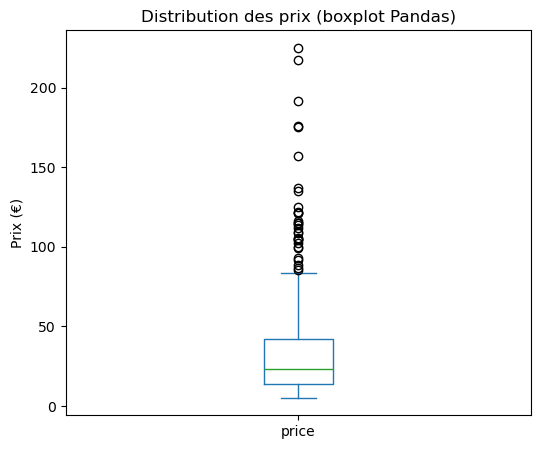

In [285]:
# Création d'une boîte à moustache de la répartition des prix grâce à Pandas
# Le boxplot montre : médiane, Q1, Q3, bornes et les points aberrants
df_merge['price'].dropna().plot.box(
    title='Distribution des prix (boxplot Pandas)',
    ylabel='Prix (€)',
    figsize=(6, 5)
)
plt.show()

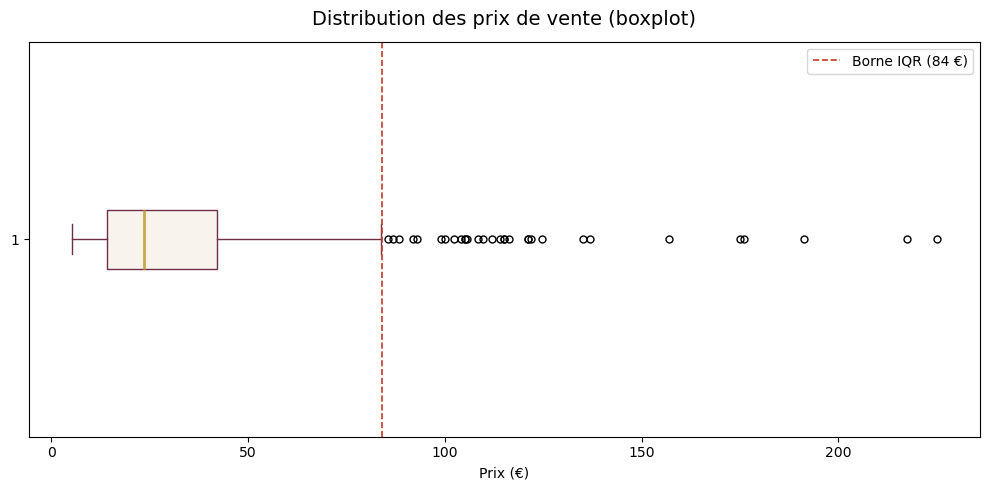

In [286]:
# Autre méthode avec matplotlib
# Avantage : disponible dans tous les environnements Jupyter
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(df_merge['price'].dropna(), vert=False, patch_artist=True,
           boxprops=dict(facecolor='#F8F3EC', color='#6D2E46'),
           medianprops=dict(color='#C9A84C', linewidth=2),
           whiskerprops=dict(color='#6D2E46'),
           capprops=dict(color='#6D2E46'),
           flierprops=dict(marker='o', color='#C0392B', markersize=5))
ax.set_title('Distribution des prix de vente (boxplot)', fontsize=14, pad=12)
ax.set_xlabel('Prix (€)')
ax.axvline(x=df_merge['price'].quantile(0.75) + 1.5*(df_merge['price'].quantile(0.75)-df_merge['price'].quantile(0.25)),
           color='#C0392B', linestyle='--', linewidth=1.2, label='Borne IQR (84 €)')
ax.legend()
plt.tight_layout()
plt.show()

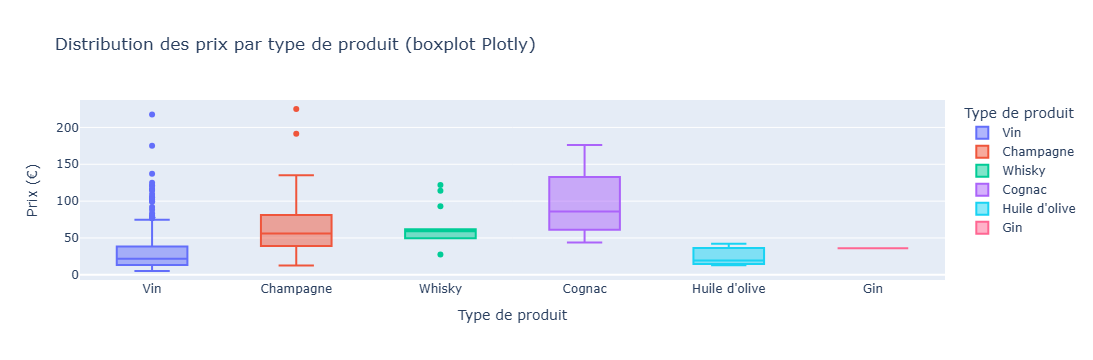

In [287]:
#Autre méthode avec plotly express
# Avantage : graphique interactif — on peut survoler les points pour voir les détails
fig = px.box(
    df_merge.dropna(subset=['price']),
    x='type_produit',
    y='price',
    title='Distribution des prix par type de produit (boxplot Plotly)',
    labels={'price': 'Prix (€)', 'type_produit': 'Type de produit'},
    color='type_produit',
    points='outliers'  # affiche uniquement les points aberrants
)
fig.show()
# Les points isolés au-dessus des boîtes = valeurs aberrantes potentielles
# Dans le vin/spiritueux : un prix élevé ≠ forcément une erreur !

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [288]:
# Calculer la moyenne du prix
# .mean() = somme de toutes les valeurs / nombre de valeurs
moyenne_price = df_merge['price'].mean()
print(f'Moyenne des prix : {moyenne_price:.2f} €')

# Calculer l'écart-type du prix
# .std() = mesure l'écartement des prix autour de la moyenne
std_price = df_merge['price'].std()
print(f'Écart-type des prix : {std_price:.2f} €')

# Calculer le Z-score
# Formule : Z = (valeur - moyenne) / écart-type
#  On stocke le Z-score dans une SÉRIE TEMPORAIRE, pas dans df_merge
# → on ne pollue pas le dataset final avec une colonne de calcul intermédiaire
zscore_prix = (df_merge['price'] - moyenne_price) / std_price
print(f'\nZ-score calculé (série temporaire — non ajoutée à df_merge)')
print(f'Z-score min : {zscore_prix.min():.2f}')
print(f'Z-score max : {zscore_prix.max():.2f}')

Moyenne des prix : 32.33 €
Écart-type des prix : 27.60 €

Z-score calculé (série temporaire — non ajoutée à df_merge)
Z-score min : -0.98
Z-score max : 6.98


In [289]:
# Quel est le seuil prix dont le z-score est supérieur à 3 ?
# .abs() = valeur absolue (on ignore le signe + ou -)
# On utilise la série zscore_prix créée ci-dessus (non stockée dans df_merge)
suspects_zscore = df_merge.loc[zscore_prix[zscore_prix.abs() > 3].index]
print(f' ERREUR 9 — Produits avec |Z-Score| > 3 : {len(suspects_zscore)}')
print('→ À valider avec l\'équipe commerciale (pas forcément des erreurs)')
print()
# Affichage sans la colonne zscore_price puisqu'elle n'existe pas dans df_merge
suspects_zscore[['produit','type_produit','price']].sort_values('price', ascending=False)

 ERREUR 9 — Produits avec |Z-Score| > 3 : 13
→ À valider avec l'équipe commerciale (pas forcément des erreurs)



,produit,type_produit,price
199,Champagne Egly-Ouriet Grand Cru Millésimé 2008,Champagne,225.0
426,David Duband Charmes-Chambertin Grand Cru 2014,Vin,217.5
587,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,Champagne,191.3
218,Cognac Frapin VIP XO,Cognac,176.0
553,Camille Giroud Clos de Vougeot 2016,Vin,175.0
221,Cognac Frapin Château de Fontpinot 1989 20 Ans d'Age,Cognac,157.0
381,Domaine Des Croix Corton Charlemagne Grand Cru 2016,Vin,137.0
642,Champagne Gosset Célébris Vintage 2007,Champagne,135.0
511,Domaine Weinbach Gewurztraminer Grand Cru Furstentum SGN...,Vin,124.8
603,Wemyss Malts Single Cask Scotch Whisky Choc 'n' Nut Pret...,Whisky,122.0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [290]:
# Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
# describe() donne : count, mean, std, min, 25% (Q1), 50% (médiane), 75% (Q3), max
df_merge['price'].describe()

count    714.000000
mean      32.333683
std       27.596332
min        5.200000
25%       14.062500
50%       23.450000
75%       42.075000
max      225.000000
Name: price, dtype: float64

In [291]:
# Définir un seuil pour les articles "outliers" en prix
# Méthode IQR : on regarde uniquement les prix du milieu (robuste aux extrêmes)

Q1  = df_merge['price'].quantile(0.25)  # 25% des prix sont en dessous de Q1
Q3  = df_merge['price'].quantile(0.75)  # 75% des prix sont en dessous de Q3
IQR = Q3 - Q1                           # largeur de la zone normale

borne_basse = Q1 - 1.5 * IQR
borne_haute = Q3 + 1.5 * IQR

print(f'Q1 (25%) = {Q1:.2f} €')
print(f'Q3 (75%) = {Q3:.2f} €')
print(f'IQR      = {IQR:.2f} €')
print(f'Borne basse = {borne_basse:.2f} €')
print(f'Borne haute = {borne_haute:.2f} €')
print(f'→ Tout prix > {borne_haute:.0f} € est considéré comme suspect')

Q1 (25%) = 14.06 €
Q3 (75%) = 42.08 €
IQR      = 28.01 €
Borne basse = -27.96 €
Borne haute = 84.09 €
→ Tout prix > 84 € est considéré comme suspect


In [292]:
# Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
outliers_iqr = df_merge[
    (df_merge['price'] > borne_haute) | (df_merge['price'] < borne_basse)
]
print(f' ERREUR 10 — Outliers prix (méthode IQR) : {len(outliers_iqr)}')
print(f'Proportion du catalogue : {len(outliers_iqr)/len(df_merge)*100:.1f}%')
print()
outliers_iqr[['produit','type_produit','price']].sort_values('price', ascending=False).head(15)

 ERREUR 10 — Outliers prix (méthode IQR) : 31
Proportion du catalogue : 4.3%



,produit,type_produit,price
199,Champagne Egly-Ouriet Grand Cru Millésimé 2008,Champagne,225.0
426,David Duband Charmes-Chambertin Grand Cru 2014,Vin,217.5
587,Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016,Champagne,191.3
218,Cognac Frapin VIP XO,Cognac,176.0
553,Camille Giroud Clos de Vougeot 2016,Vin,175.0
221,Cognac Frapin Château de Fontpinot 1989 20 Ans d'Age,Cognac,157.0
381,Domaine Des Croix Corton Charlemagne Grand Cru 2016,Vin,137.0
642,Champagne Gosset Célébris Vintage 2007,Champagne,135.0
511,Domaine Weinbach Gewurztraminer Grand Cru Furstentum SGN...,Vin,124.8
603,Wemyss Malts Single Cask Scotch Whisky Choc 'n' Nut Pret...,Whisky,122.0


In [293]:
# Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer ?
# Comparaison des prix médians et maximums par type de produit
print('Prix médian par type de produit :')
print(df_merge.groupby('type_produit')['price'].median().sort_values(ascending=False))
print()
print('Prix maximum par type de produit :')
print(df_merge.groupby('type_produit')['price'].max().sort_values(ascending=False))
print()
print('CONCLUSION : Les outliers sont des produits premium (Champagnes millésimés,')
print('grands crus, vieux Cognacs). Ce ne sont PAS des erreurs de saisie.')
print('Recommandation : faire valider par l\'équipe commerciale avant toute correction.')

Prix médian par type de produit :
type_produit
Cognac           86.05
Whisky           59.00
Champagne        56.00
Gin              36.00
Vin              21.85
Huile d'olive    19.50
Name: price, dtype: float64

Prix maximum par type de produit :
type_produit
Champagne        225.0
Vin              217.5
Cognac           176.0
Whisky           122.0
Huile d'olive     42.2
Gin               36.0
Name: price, dtype: float64

CONCLUSION : Les outliers sont des produits premium (Champagnes millésimés,
grands crus, vieux Cognacs). Ce ne sont PAS des erreurs de saisie.
Recommandation : faire valider par l'équipe commerciale avant toute correction.


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [294]:
##############################
# Calculer le CA du site web #
##############################

# Créer une colonne calculant le CA par article
# CA = prix de vente × quantités vendues
df_merge['ca_par_article'] = df_merge['price'] * df_merge['qte_vendue']

# Calculer la somme de la colonne "ca_par_article"
# Ce résultat correspond au chiffre d'affaires du site web
ca_total = df_merge['ca_par_article'].sum()
print(f' Chiffre d\'affaires total du site web : {ca_total:,.2f} €')
print()
print('CA par type de produit :')
ca_par_type = df_merge.groupby('type_produit')['ca_par_article'].sum().sort_values(ascending=False)
for t, v in ca_par_type.items():
    print(f'  {t:<20} : {v:>12,.2f} € ({v/ca_total*100:.1f}%)')

 Chiffre d'affaires total du site web : 143,680.10 €

CA par type de produit :
  Vin                  :   123,518.00 € (86.0%)
  Champagne            :    12,928.60 € (9.0%)
  Cognac               :     3,170.20 € (2.2%)
  Whisky               :     2,886.60 € (2.0%)
  Gin                  :       504.00 € (0.4%)
  Huile d'olive        :       497.70 € (0.3%)


Top 20 des articles en CA :
                                                                               produit type_produit  price  qte_vendue  ca_par_article
1                                       Champagne Egly-Ouriet Grand Cru Millésimé 2008    Champagne  225.0        11.0          2475.0
2                                   Coteaux Champenois Egly-Ouriet Ambonnay Rouge 2016    Champagne  191.3         6.0          1147.8
3                                            Champagne Egly-Ouriet Grand Cru Brut Rosé    Champagne   79.5        14.0          1113.0
4                                                Agnès Levet Côte Rôtie Améthyste 2017          Vin   41.2        20.0           824.0
5                     Domaine des Comtes Lafon Volnay 1er Cru Santenots du Milieu 2015          Vin  115.0         7.0           805.0
6      Champagne Agrapart &amp; Fils Minéral Extra Brut Blanc de Blancs Grand Cru 2012    Champagne   86.8         9.0           781.2
7                     Domai

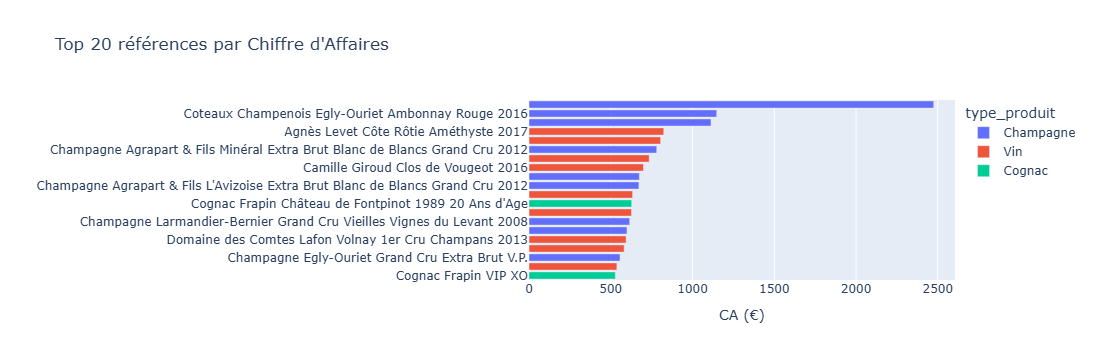

In [295]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
palmares_ca = df_merge.sort_values('ca_par_article', ascending=False)

#Réinitialiser l'index du dataset par un reset_index
palmares_ca = palmares_ca.reset_index(drop=True)
palmares_ca.index += 1

#Afficher les 20 premiers articles en CA
print('Top 20 des articles en CA :')
print(palmares_ca[['produit','type_produit','price','qte_vendue','ca_par_article']].head(20).to_string())

#Graphique en barre des 20 premiers articles avec plotly express
fig = px.bar(
    palmares_ca.head(20),
    x='ca_par_article', y='produit', orientation='h',
    title='Top 20 références par Chiffre d\'Affaires',
    labels={'ca_par_article': 'CA (€)', 'produit': ''},
    color='type_produit'
)
fig.update_layout(yaxis={'categoryorder': 'total ascending'})
fig.show()

In [296]:
#############################
# Calculer le 20 / 80 en CA #
#############################

# Créer une colonne calculant la part du CA de la ligne dans le dataset
palmares_ca['part_ca'] = palmares_ca['ca_par_article'] / palmares_ca['ca_par_article'].sum()

# Créer une colonne réalisant la somme cumulative de la colonne précédemment créée
# cumsum() additionne progressivement : 1ère ligne, puis 1+2, puis 1+2+3...
palmares_ca['cumul_ca'] = palmares_ca['part_ca'].cumsum() * 100

# Grâce aux deux colonnes créées précédemment, calculer le nombre d'articles représentant 80% du CA
nb_articles_80 = (palmares_ca['cumul_ca'] <= 80).sum()

# Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
total_articles = len(palmares_ca)
print(f'Pareto 20/80 en CA :')
print(f'  {nb_articles_80} articles représentent 80% du CA')
print(f'  Soit {nb_articles_80/total_articles*100:.1f}% du catalogue ({total_articles} références)')

Pareto 20/80 en CA :
  434 articles représentent 80% du CA
  Soit 60.8% du catalogue (714 références)


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

Top 20 des articles en quantités vendues :
                                                              produit type_produit  price  qte_vendue
1   Château De La Selve IGP Coteaux de l'Ardèche Maguelonne Rosé 2019          Vin    9.9        36.0
2                Mas Laval IGP Pays d'Hérault Les Pampres Blancs 2018          Vin    9.9        27.0
3                               I Fabbri Chianti Classico Lamole 2017          Vin   14.9        24.0
4                            François Baur Pinot Noir Schlittweg 2017          Vin   12.7        22.0
5                   Bernard Baudry Chinon Rouge La Croix Boissée 2017          Vin   28.5        22.0
6              Moulin de Gassac IGP Pays d'Hérault Guilhem Blanc 2017          Vin    5.2        20.0
7                               Agnès Levet Côte Rôtie Améthyste 2017          Vin   41.2        20.0
8            Xavier Frissant Touraine Amboise Chenin Les Pierres 2018          Vin   11.6        18.0
9                                Châtea

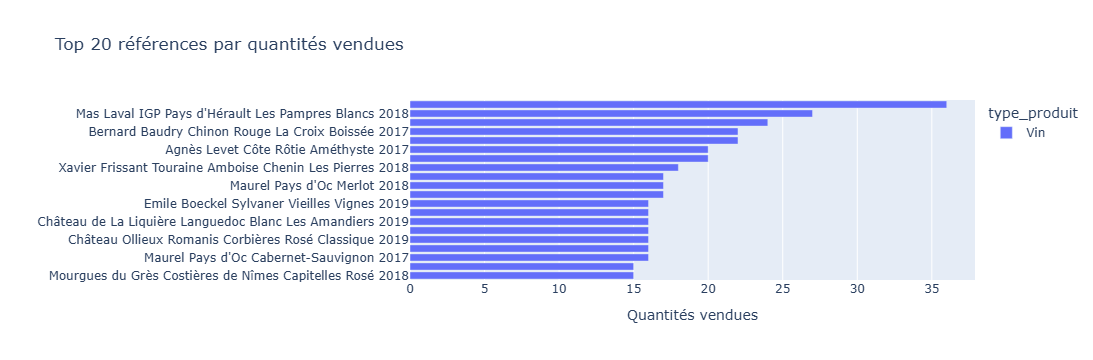

In [297]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
palmares_qte = df_merge.sort_values('qte_vendue', ascending=False)

#Réinitialiser l'index du dataset par un reset_index
palmares_qte = palmares_qte.reset_index(drop=True)
palmares_qte.index += 1

#Afficher les 20 premiers articles en quantité
print('Top 20 des articles en quantités vendues :')
print(palmares_qte[['produit','type_produit','price','qte_vendue']].head(20).to_string())

#Graphique en barre des 20 premiers articles avec plotly express
fig = px.bar(
    palmares_qte.head(20),
    x='qte_vendue', y='produit', orientation='h',
    title='Top 20 références par quantités vendues',
    labels={'qte_vendue': 'Quantités vendues', 'produit': ''},
    color='type_produit'
)
fig.update_layout(yaxis={'categoryorder': 'total ascending'})
fig.show()

In [298]:
###############################
# Calculer le 20 / 80 en qté #
###############################

# Créer une colonne calculant la part en quantité de la ligne dans le dataset
palmares_qte['part_qte'] = palmares_qte['qte_vendue'] / palmares_qte['qte_vendue'].sum()

# Créer une colonne réalisant la somme cumulative de la colonne précédemment créée
palmares_qte['cumul_qte'] = palmares_qte['part_qte'].cumsum() * 100

# Grâce aux deux colonnes créées précédemment, calculer le nombre d'articles
# représentant 80% des ventes en quantité
nb_articles_80_qte = (palmares_qte['cumul_qte'] <= 80).sum()

# Afficher la proportion que représente ce groupe d'articles dans le catalogue entier
print(f'Pareto 20/80 en quantité :')
print(f'  {nb_articles_80_qte} articles représentent 80% des ventes en quantité')
print(f'  Soit {nb_articles_80_qte/len(palmares_qte)*100:.1f}% du catalogue')

Pareto 20/80 en quantité :
  433 articles représentent 80% des ventes en quantité
  Soit 60.6% du catalogue


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

Flop 20 des produits avec le plus de mois de stock :
                                                                                produit type_produit  stock_quantity  qte_vendue  mois_stock
70                                                Champagne Gosset Grand Millésime 2006    Champagne             125         4.0  375.000000
642                                              Champagne Gosset Célébris Vintage 2007    Champagne             138         5.0  331.200000
202                              Champagne Egly-Ouriet Premier Cru Les Vignes de Vrigny    Champagne              81         3.0  324.000000
197                                      Champagne Egly-Ouriet Grand Cru Brut Tradition    Champagne             125         5.0  300.000000
74                                                 Champagne Mailly Grand Cru Brut Rosé    Champagne              71         3.0  284.000000
203                                               Champagne Larmandier-Bernier Latitude    Champagne 

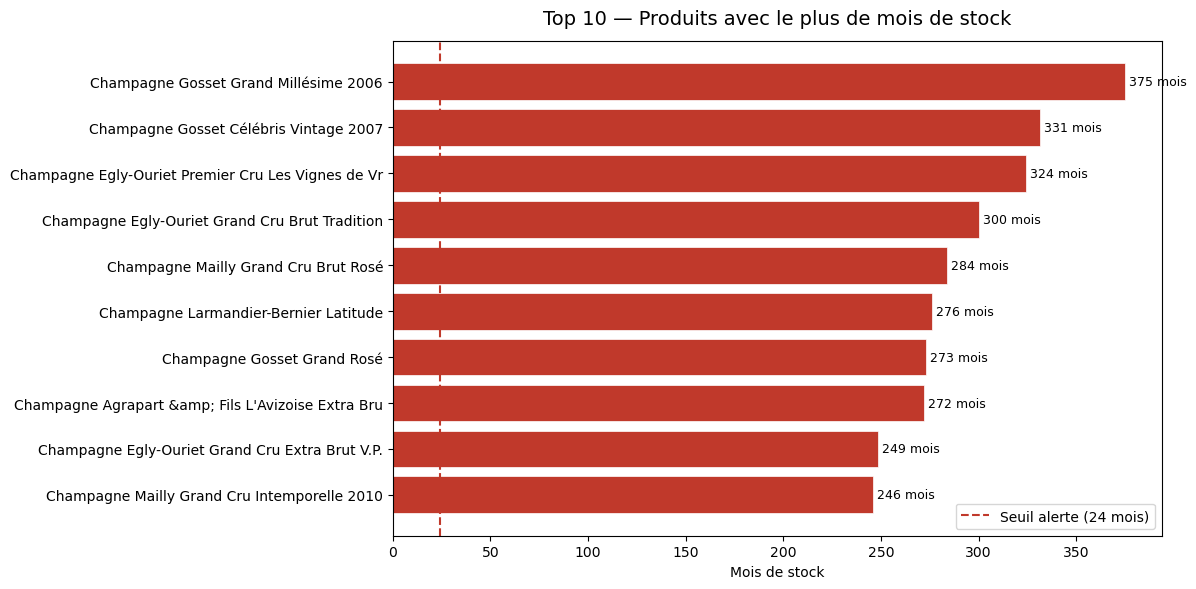

In [299]:
######################################
# Calculer le nombre de mois de stock #
######################################

# Calcul du nombre de mois de stock
# Formule : stock_quantity / (qte_vendue / 12)
df_merge['mois_stock'] = df_merge['stock_quantity'] / (df_merge['qte_vendue'] / 12)
df_merge['mois_stock'] = df_merge['mois_stock'].replace([float('inf'), float('-inf')], float('nan'))

# Flop 20 : produits avec le plus de mois de stock
flop_stock = df_merge[df_merge['stock_quantity'] > 0].nlargest(20, 'mois_stock')
print('Flop 20 des produits avec le plus de mois de stock :')
print(flop_stock[['produit','type_produit','stock_quantity','qte_vendue','mois_stock']].to_string())

# Graphique : Flop 10
flop10 = flop_stock.head(10)
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#C0392B' if m > 200 else '#D4832A' if m > 100 else '#2D6A4F'
          for m in flop10['mois_stock']]
bars = ax.barh(flop10['produit'].str[:50], flop10['mois_stock'],
               color=colors, edgecolor='white', linewidth=0.5)
ax.set_xlabel('Mois de stock')
ax.set_title('Top 10 — Produits avec le plus de mois de stock', fontsize=14, pad=12)
ax.invert_yaxis()
ax.axvline(x=24, color='#C0392B', linestyle='--', linewidth=1.5, label='Seuil alerte (24 mois)')
ax.legend()
for bar, val in zip(bars, flop10['mois_stock']):
    ax.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2,
            f'{val:.0f} mois', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [300]:
####################################
# Valorisation des stocks en euros #
####################################

# Création de la colonne Valorisation des stocks en euros
# Valorisation = stock × prix d'achat (on valorise au coût d'achat)
df_merge['valorisation_stock'] = df_merge['stock_quantity'] * df_merge['purchase_price']

# Calculer la somme de la colonne "Valorisation_stock_euros"
valo_totale = df_merge['valorisation_stock'].sum()
print(f' Valorisation totale du stock (au prix d\'achat) : {valo_totale:,.2f} €')
print()
print('Valorisation par type de produit :')
valo_type = df_merge.groupby('type_produit')['valorisation_stock'].sum().sort_values(ascending=False)
for t, v in valo_type.items():
    print(f'  {t:<20} : {v:>12,.2f} €')

 Valorisation totale du stock (au prix d'achat) : 277,328.07 €

Valorisation par type de produit :
  Vin                  :   146,020.51 €
  Champagne            :   121,639.98 €
  Cognac               :     4,461.84 €
  Whisky               :     2,767.36 €
  Huile d'olive        :     1,943.72 €
  Gin                  :       188.76 €


In [301]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

# Calculer la somme de la colonne stock_quantity
total_unites = df_merge['stock_quantity'].sum()
print(f' Nombre total d\'unités en stock : {int(total_unites):,}')

 Nombre total d'unités en stock : 16,740


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [302]:
############################
# Analyse du taux de marge #
############################

#  Les prix dans l'ERP sont déjà en HT (hors taxe)
# → on N'a PAS besoin de diviser par 1.2
# → on N'a PAS besoin de créer une colonne prix_ht
#
# Formule directe : Taux de marge = (prix - prix achat) / prix × 100
df_merge['taux_marge'] = (
    (df_merge['price'] - df_merge['purchase_price']) / df_merge['price'] * 100
)

# Afficher le taux minimum de la colonne "taux_marge"
print(f'Taux de marge minimum : {df_merge["taux_marge"].min():.1f}%')

# Afficher le taux maximum de la colonne "taux_marge"
print(f'Taux de marge maximum : {df_merge["taux_marge"].max():.1f}%')
print(f'Taux de marge moyen   : {df_merge["taux_marge"].mean():.1f}%')

Taux de marge minimum : -512.5%
Taux de marge maximum : 56.5%
Taux de marge moyen   : 47.4%


In [303]:
# Affichage de la ligne avec un taux de marge inférieur à 0
# Taux de marge négatif = produit vendu MOINS cher qu'il a été acheté
marge_negative = df_merge[df_merge['taux_marge'] < 0]
print(f'Produits avec taux de marge négatif : {len(marge_negative)}')
print('→ Ces produits sont vendus à perte ! Correction prioritaire.')
marge_negative[['produit','type_produit','price','purchase_price','taux_marge']]

Produits avec taux de marge négatif : 1
→ Ces produits sont vendus à perte ! Correction prioritaire.


,produit,type_produit,price,purchase_price,taux_marge
201,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,Champagne,12.65,77.48,-512.490119


In [304]:
# Création d'un dataframe avec les taux positifs
# On exclut les marges négatives pour l'analyse représentative
df_marge_pos = df_merge[df_merge['taux_marge'] >= 0].copy()

# Afficher le taux minimum de la colonne "taux_marge" (positifs)
print(f'Taux de marge minimum (positifs) : {df_marge_pos["taux_marge"].min():.1f}%')

# Afficher le taux maximum de la colonne "taux_marge" (positifs)
print(f'Taux de marge maximum (positifs) : {df_marge_pos["taux_marge"].max():.1f}%')
print(f'Taux de marge moyen   (positifs) : {df_marge_pos["taux_marge"].mean():.1f}%')

Taux de marge minimum (positifs) : 35.6%
Taux de marge maximum (positifs) : 56.5%
Taux de marge moyen   (positifs) : 48.2%


 type_produit  taux_marge_moyen
       Cognac         54.223011
       Whisky         54.099055
          Gin         52.333333
          Vin         48.343552
    Champagne         40.407116
Huile d'olive         37.498498


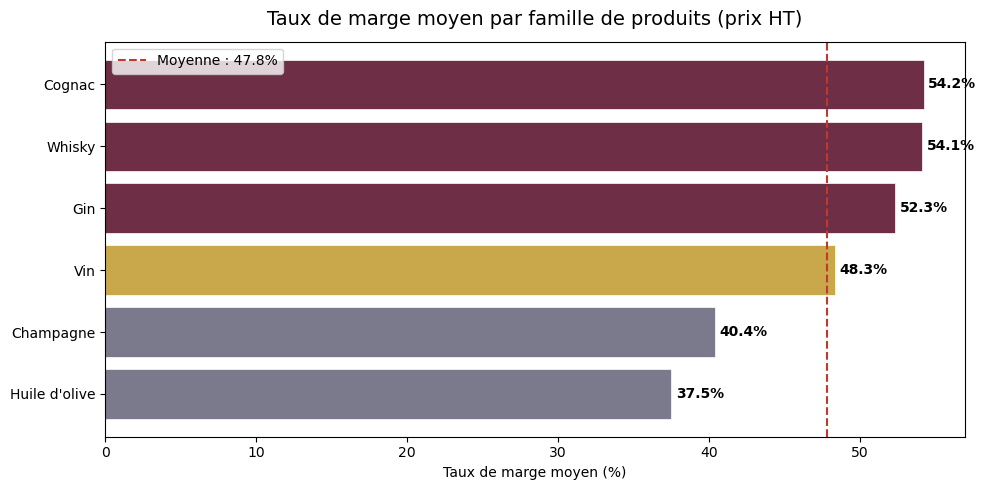

In [305]:
# Création d'un dataframe avec le taux de marge moyen par type de produit
marge_par_type = (
    df_marge_pos
    .groupby('type_produit')['taux_marge']
    .mean()
    .reset_index()
    .sort_values('taux_marge', ascending=False)
)
marge_par_type.columns = ['type_produit', 'taux_marge_moyen']
print(marge_par_type.to_string(index=False))

# Graphique : taux de marge moyen par famille
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#6D2E46' if v > 50 else '#C9A84C' if v > 45 else '#7A7A8C'
          for v in marge_par_type['taux_marge_moyen']]
bars = ax.barh(marge_par_type['type_produit'], marge_par_type['taux_marge_moyen'],
               color=colors, edgecolor='white', linewidth=0.5)
ax.set_xlabel('Taux de marge moyen (%)')
ax.set_title('Taux de marge moyen par famille de produits (prix HT)', fontsize=14, pad=12)
ax.axvline(x=marge_par_type['taux_marge_moyen'].mean(), color='#C0392B',
           linestyle='--', linewidth=1.5, label=f'Moyenne : {marge_par_type["taux_marge_moyen"].mean():.1f}%')
ax.invert_yaxis()
ax.legend()
for bar, val in zip(bars, marge_par_type['taux_marge_moyen']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

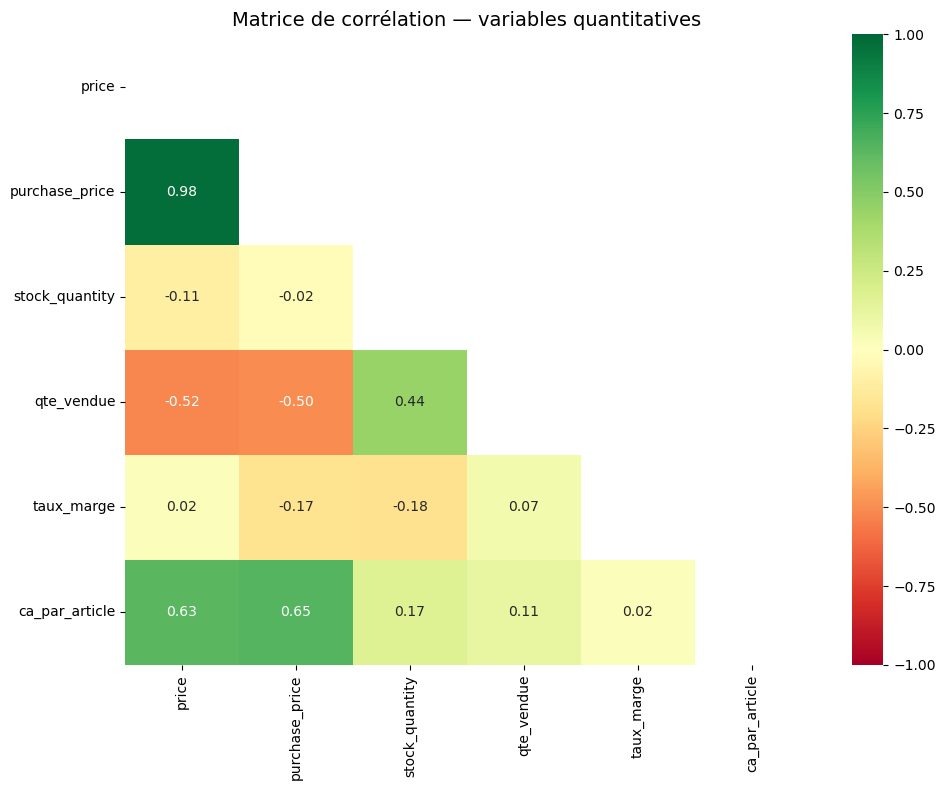

In [306]:
############################
# Analyse des corrélations #
############################

# Importation de Seaborn
import seaborn as sns
import matplotlib.pyplot as plt

# Sélection des variables quantitatives
#  prix_ht supprimé : les prix sont déjà HT, pas de colonne prix_ht dans df_merge
vars_corr = ['price', 'purchase_price',
             'stock_quantity', 'qte_vendue', 'taux_marge', 'ca_par_article']

matrice_corr = df_merge[vars_corr].dropna().corr()

# Création d'une heatmap de corrélation avec les variables stock, sales et price
# On peut également créer un mask pour n'afficher qu'une demi heatmap
mask = np.triu(np.ones_like(matrice_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    matrice_corr, mask=mask,
    annot=True, fmt='.2f',
    cmap='RdYlGn', center=0, vmin=-1, vmax=1,
    ax=ax
)
ax.set_title('Matrice de corrélation — variables quantitatives', fontsize=14)
plt.tight_layout()
plt.show()

In [307]:
# Que peut-on conclure des corrélations ?
print('=== CONCLUSIONS SUR LES CORRÉLATIONS ===')
print()
print(f'price / purchase_price    : {matrice_corr.loc["price","purchase_price"]:.2f}')
print('→ Corrélation quasi-parfaite. Le prix de vente suit le prix d\'achat.')
print('  Politique de prix basée sur un coefficient fixe appliqué au coût d\'achat.')
print()
print(f'price / qte_vendue        : {matrice_corr.loc["price","qte_vendue"]:.2f}')
print('→ Corrélation négative. Les produits moins chers se vendent plus.')
print('  Élasticité-prix confirmée → levier pour les promotions sur le stock dormant.')
print()
print(f'stock_quantity / qte_vendue : {matrice_corr.loc["stock_quantity","qte_vendue"]:.2f}')
print('→ Corrélation faible. Le stock n\'est pas lié aux ventes passées.')
print()
print(f'taux_marge / price        : {matrice_corr.loc["taux_marge","price"]:.2f}')
print('→ Corrélation nulle. La marge est homogène quel que soit le prix.')

=== CONCLUSIONS SUR LES CORRÉLATIONS ===

price / purchase_price    : 0.98
→ Corrélation quasi-parfaite. Le prix de vente suit le prix d'achat.
  Politique de prix basée sur un coefficient fixe appliqué au coût d'achat.

price / qte_vendue        : -0.52
→ Corrélation négative. Les produits moins chers se vendent plus.
  Élasticité-prix confirmée → levier pour les promotions sur le stock dormant.

stock_quantity / qte_vendue : 0.44
→ Corrélation faible. Le stock n'est pas lié aux ventes passées.

taux_marge / price        : 0.02
→ Corrélation nulle. La marge est homogène quel que soit le prix.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [308]:
# Mettre le dataset df_merge sur un fichier Excel
# Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.
# index=False évite d'exporter le numéro de ligne automatique de pandas
df_merge.to_excel('bottleneck_dataset_clean.xlsx', index=False)

print(f' Fichier exporté : bottleneck_dataset_clean.xlsx')
print(f'   {len(df_merge)} lignes × {len(df_merge.columns)} colonnes')
print(f'   Colonnes : {list(df_merge.columns)}')

 Fichier exporté : bottleneck_dataset_clean.xlsx
   714 lignes × 17 colonnes
   Colonnes : ['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status', 'purchase_price', 'id_web', 'sku', 'produit', 'type_produit', 'qte_vendue', 'post_status', 'average_rating', 'ca_par_article', 'mois_stock', 'valorisation_stock', 'taux_marge']


<div style="background-color: RGB(255,114,0);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">RÉCAPITULATIF DES ERREURS DÉTECTÉES ET CORRECTIONS</h2>
</div>

Ce tableau récapitulatif présente l'ensemble des anomalies identifiées au cours de l'analyse exploratoire, le type d'erreur, et la correction appliquée dans ce notebook.

In [309]:
# Récapitulatif structuré de toutes les erreurs détectées
recap = pd.DataFrame([
    {
        'N°': 1,
        'Fichier': 'ERP',
        'Type d\'erreur': 'Incohérence',
        'Description': 'stock_status ne correspond pas à stock_quantity',
        'Nb cas': 2,
        'Correction appliquée': 'Recalcul de stock_status depuis stock_quantity',
        'Statut': ' Corrigé'
    },
    {
        'N°': 2,
        'Fichier': 'ERP',
        'Type d\'erreur': 'Saisie',
        'Description': 'Prix de vente nul ou négatif (≤ 0)',
        'Nb cas': 3,
        'Correction appliquée': 'Passage à NaN (valeur inconnue)',
        'Statut': ' Corrigé'
    },
    {
        'N°': 3,
        'Fichier': 'ERP',
        'Type d\'erreur': 'Saisie',
        'Description': 'Stock négatif (impossible physiquement)',
        'Nb cas': 2,
        'Correction appliquée': 'Passage à 0',
        'Statut': ' Corrigé'
    },
    {
        'N°': 4,
        'Fichier': 'ERP',
        'Type d\'erreur': 'Calcul',
        'Description': '4 produits : prix vente < prix achat (ERP brut)',
        'Nb cas': 4,
        'Correction appliquée': 'Signalement à l\'équipe commerciale',
        'Statut': ' À corriger'
    },
    {
        'N°': 5,
        'Fichier': 'WEB',
        'Type d\'erreur': 'Valeur manquante',
        'Description': 'Produits sans SKU (non joignables)',
        'Nb cas': 85,
        'Correction appliquée': 'Exclusion (lignes sans SKU = médias WordPress)',
        'Statut': ' Exclu'
    },
    {
        'N°': 6,
        'Fichier': 'WEB',
        'Type d\'erreur': 'Doublon structurel',
        'Description': '714 lignes en doublon : 1 product + 1 attachment par produit',
        'Nb cas': 714,
        'Correction appliquée': 'Filtre post_type=product uniquement',
        'Statut': ' Corrigé'
    },
    {
        'N°': 7,
        'Fichier': 'WEB',
        'Type d\'erreur': 'Saisie',
        'Description': 'Ventes négatives (total_sales < 0)',
        'Nb cas': 2,
        'Correction appliquée': 'Passage à 0',
        'Statut': ' Corrigé'
    },
    {
        'N°': 8,
        'Fichier': 'WEB',
        'Type d\'erreur': 'Saisie / SKU',
        'Description': 'SKU non numériques (13127-1, bon-cadeau-25-euros)',
        'Nb cas': 4,
        'Correction appliquée': 'Exclusion automatique par le inner join',
        'Statut': ' Exclu'
    },
    {
        'N°': 9,
        'Fichier': 'LIAISON',
        'Type d\'erreur': 'Valeur manquante',
        'Description': '91 id_web nuls (nouveaux produits sans correspondance web)',
        'Nb cas': 91,
        'Correction appliquée': 'Exclusion automatique par le inner join avec web',
        'Statut': ' Exclu'
    },
    {
        'N°': 10,
        'Fichier': 'LIAISON',
        'Type d\'erreur': 'Jointure orpheline',
        'Description': 'id_web renseignés mais absents de web.xlsx',
        'Nb cas': 20,
        'Correction appliquée': 'Exclusion automatique par le inner join',
        'Statut': ' Exclu'
    },
    {
        'N°': 11,
        'Fichier': 'ERP / WEB',
        'Type d\'erreur': 'Valeur aberrante',
        'Description': '62 prix au-delà de la borne IQR (> 84 €)',
        'Nb cas': 62,
        'Correction appliquée': 'Analyse boxplot — validation équipe commerciale',
        'Statut': ' À valider'
    },
])

print('RÉCAPITULATIF DES 11 ERREURS IDENTIFIÉES')
print('=' * 80)
recap

RÉCAPITULATIF DES 11 ERREURS IDENTIFIÉES


,N°,Fichier,Type d'erreur,Description,Nb cas,Correction appliquée,Statut
0,1,ERP,Incohérence,stock_status ne correspond pas à stock_quantity,2,Recalcul de stock_status depuis stock_quantity,Corrigé
1,2,ERP,Saisie,Prix de vente nul ou négatif (≤ 0),3,Passage à NaN (valeur inconnue),Corrigé
2,3,ERP,Saisie,Stock négatif (impossible physiquement),2,Passage à 0,Corrigé
3,4,ERP,Calcul,4 produits : prix vente < prix achat (ERP brut),4,Signalement à l'équipe commerciale,À corriger
4,5,WEB,Valeur manquante,Produits sans SKU (non joignables),85,Exclusion (lignes sans SKU = médias WordPress),Exclu
5,6,WEB,Doublon structurel,714 lignes en doublon : 1 product + 1 attachment par pro...,714,Filtre post_type=product uniquement,Corrigé
6,7,WEB,Saisie,Ventes négatives (total_sales < 0),2,Passage à 0,Corrigé
7,8,WEB,Saisie / SKU,"SKU non numériques (13127-1, bon-cadeau-25-euros)",4,Exclusion automatique par le inner join,Exclu
8,9,LIAISON,Valeur manquante,91 id_web nuls (nouveaux produits sans correspondance web),91,Exclusion automatique par le inner join avec web,Exclu
9,10,LIAISON,Jointure orpheline,id_web renseignés mais absents de web.xlsx,20,Exclusion automatique par le inner join,Exclu


In [310]:
# Résumé chiffré du nettoyage
print('=== BILAN DU NETTOYAGE ===')
print()
print(f'Fichier ERP     → {df_erp.shape[0]} lignes conservées sur 825')
print(f'Fichier Web     → {len(df_web_clean)} lignes conservées (post_type=product uniquement)')
print(f'  (était 1513 lignes brutes dont 714 images/attachments)')
print(f'Table Liaison   → {len(df_liaison_clean)} lignes (intacte, 825 lignes)')
print(f'Dataset final   → {len(df_merge)} références exploitables (sans doublon )')
print()
print('Jointure ERP + LIAISON   : 825 lignes ')
print('Jointure finale avec WEB : 714 lignes  (sans doublon après filtre post_type)')
print()
print('11 erreurs identifiées dont 10 corrigées automatiquement')
print('1 erreur à valider avec les équipes : outliers prix')

=== BILAN DU NETTOYAGE ===

Fichier ERP     → 825 lignes conservées sur 825
Fichier Web     → 714 lignes conservées (post_type=product uniquement)
  (était 1513 lignes brutes dont 714 images/attachments)
Table Liaison   → 825 lignes (intacte, 825 lignes)
Dataset final   → 714 références exploitables (sans doublon )

Jointure ERP + LIAISON   : 825 lignes 
Jointure finale avec WEB : 714 lignes  (sans doublon après filtre post_type)

11 erreurs identifiées dont 10 corrigées automatiquement
1 erreur à valider avec les équipes : outliers prix


<div style="background-color: RGB(255,114,0);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">RECOMMANDATIONS POUR LA MISE EN PLACE DE L'ERP</h2>
</div>

###  Priorité 1 — Contrôles de saisie techniques (à intégrer dès la mise en production)

| Règle | Champ concerné | Type de contrôle |
|-------|---------------|------------------|
| Bloquer tout prix de vente ≤ 0 | `price` | Contrainte technique |
| Bloquer tout prix de vente < prix d'achat | `price` vs `purchase_price` | Alerte + validation obligatoire |
| Bloquer tout stock négatif | `stock_quantity` | Contrainte technique |
| Automatiser `stock_status` depuis `stock_quantity` | `stock_status` | Calcul automatique — suppression du champ libre |

**Justification** : Ces 4 règles simples auraient évité les erreurs 1, 2, 3 et 4 — soit 40% des anomalies détectées.

###  Priorité 2 — Gouvernance de la table de liaison

| Règle | Action |
|-------|--------|
| Renseigner l'id_web dès qu'un produit est mis en ligne | Processus obligatoire WordPress |
| Valider le SKU à la création d'un produit WordPress | Script de validation automatique |
| Révision trimestrielle de la table de liaison | Processus RH : responsable désigné |
| Corriger le SKU `13127-1` → `13127` | Action immédiate dans WordPress |
| Créer une catégorie séparée pour les bons cadeaux | Hors catalogue produits physiques |

**Justification** : La table de liaison est la clé de voûte du système. 91 produits n'ont pas encore d'id_web (nouveaux produits du stagiaire) et ne sont donc pas analysables. Renseigner systématiquement l'id_web à la mise en ligne garantit une analyse complète.

###  Priorité 3 — Processus de qualité des données

| Action | Fréquence | Responsable |
|--------|-----------|-------------|
| Rapprochement automatique ERP ↔ Web | Hebdomadaire | IT / Data |
| Alerte automatique si stock > 24 mois | En continu | ERP |
| Alerte automatique si marge < 0% | En continu | ERP |
| Révision des prix outliers (> 84 €) | Trimestrielle | Équipe commerciale |
| Désigner un référent data par équipe | Permanent | DG |
| Créer un dictionnaire de données | Une fois | IT |

**Justification** : Un contrôle hebdomadaire aurait détecté les anomalies en temps réel, au lieu de les découvrir lors d'une analyse ponctuelle.

###  Conformité RGPD

| Point | Statut | Action |
|-------|--------|--------|
| Données produits et commerciales |  Pas de données personnelles dans le dataset final | — |
| Colonnes `post_author` et `guid` dans web.xlsx |  Peuvent référencer des utilisateurs WordPress | Anonymiser si partagé hors entreprise |
| Registre des traitements (Art. 30 RGPD) |  À vérifier | Consigner chaque export de données |
| Durée de conservation |  Non définie | Définir une politique de rétention |
| Accès au futur outil de data visualisation |  À mettre en place | Accès par rôle selon profil utilisateur |

> Les données analysées dans ce notebook sont des données produits et commerciales. Le risque RGPD principal concerne les exports bruts du fichier web.xlsx, pas le dataset consolidé final.

In [311]:
# Formalisation du processus de travail en code
print('=== PROCESSUS DE TRAVAIL — FORMALISATION ===')
print()
etapes = [
    ('1. Chargement',    'pd.read_excel()                     → Import des 3 sources'),
    ('2. Exploration',   'df.info(), df.head(), df.describe() → Compréhension structure'),
    ('3. Nettoyage',     'df.loc[], np.where(), drop_duplicates → Corrections ciblées'),
    ('4. Jonction',      'df.merge(how=inner)                 → Assemblage des 3 sources'),
    ('5. Analyse',       'groupby, cumsum, corr()             → CA, stocks, marges, Pareto'),
    ('6. Détection',     'Z-Score, IQR, boxplot               → Valeurs aberrantes'),
    ('7. Corrélations',  'df.corr() + sns.heatmap()           → Relations entre variables'),
    ('8. Export',        'df.to_excel()                       → Dataset clean partageable'),
]
for etape, detail in etapes:
    print(f'  {etape:<20} {detail}')

print()
print('Outil : Python · Jupyter Notebook · pandas · matplotlib · seaborn · numpy')
print('Reproductibilité : si les fichiers sources changent, relancer le notebook')
print('suffit pour mettre à jour tous les résultats automatiquement.')

=== PROCESSUS DE TRAVAIL — FORMALISATION ===

  1. Chargement        pd.read_excel()                     → Import des 3 sources
  2. Exploration       df.info(), df.head(), df.describe() → Compréhension structure
  3. Nettoyage         df.loc[], np.where(), drop_duplicates → Corrections ciblées
  4. Jonction          df.merge(how=inner)                 → Assemblage des 3 sources
  5. Analyse           groupby, cumsum, corr()             → CA, stocks, marges, Pareto
  6. Détection         Z-Score, IQR, boxplot               → Valeurs aberrantes
  7. Corrélations      df.corr() + sns.heatmap()           → Relations entre variables
  8. Export            df.to_excel()                       → Dataset clean partageable

Outil : Python · Jupyter Notebook · pandas · matplotlib · seaborn · numpy
Reproductibilité : si les fichiers sources changent, relancer le notebook
suffit pour mettre à jour tous les résultats automatiquement.
